# Comprendre et construire un moteur de recommandation vidéo
**Stage S7 · Démonstration sur les interactions de KuaiRec**

Comment choisir dix vidéos pour une personne, et comment vérifier que le classement a du sens ? Nous allons suivre une interaction depuis le CSV jusqu’à la liste d’identifiants que renvoie l’API. Le point de comparaison sera une règle simple qui propose les mêmes scores de popularité à tous.

**Pour une première lecture**, suis les exemples de ratio, de masque et de classement. Les tableaux et figures sous les cellules viennent de leur exécution. **Pour refaire l’expérience**, ouvre ce notebook dans Jupyter, redémarre le noyau Python et exécute les cellules dans l’ordre. Le CSV peut rester sur le disque D: ou se trouver à côté du notebook. Les nouveaux fichiers sont écrits dans le sous-dossier `resultats_pedagogiques` du dossier d’exécution.

## 1. Préparer l’expérience

Un *paramètre* est un choix explicite de l’expérience. Le seuil transforme une durée relative en étiquette. La lettre K désigne la longueur de la liste évaluée. La graine permet de reproduire les tirages. Nous expliquerons les rangs de SVD et les poids de l’hybride avant leur utilisation.

In [1]:
import hashlib
import json
import os
import platform
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy.stats import rankdata
from sklearn.model_selection import train_test_split
from sklearn.utils.extmath import randomized_svd

GRAINE = 42
SEUIL = 0.8
K = 10
RANGS_SVD = [16, 32, 64]
POIDS_HYBRIDES = [0.0, 0.25, 0.5, 0.75, 1.0]

Le notebook cherche d’abord le chemin indiqué par la variable d’environnement `RECO_CSV`. Sans ce réglage, il cherche le CSV à côté du notebook, puis dans le dossier `data/` à la racine du dépôt.

In [57]:
# Recherche du CSV : variable RECO_CSV, puis dossier du notebook, puis dossier data/ du dépôt.
import os
_candidats = [os.environ.get("RECO_CSV"), "small_matrix.csv", "../data/small_matrix.csv"]
Fichier = next((Path(c) for c in _candidats if c and Path(c).is_file()), Path("small_matrix.csv"))
assert Fichier.is_file(), f"CSV introuvable : {Fichier}"

sortie = Path("resultats_pedagogiques")
sortie.mkdir(exist_ok=True)
versions = {
    "python": platform.python_version(), "pandas": pd.__version__,
    "numpy": np.__version__, "scipy": scipy.__version__,
    "scikit-learn": sklearn.__version__,
}
print(Fichier.resolve())
print(versions)

D:\Projet_final_stage\Prototype_recommandation_pedagogique\small_matrix.csv
{'python': '3.14.7', 'pandas': '3.1.1', 'numpy': '2.5.5', 'scipy': '1.18.1', 'scikit-learn': '1.9.1'}


## 2. Que représente une ligne du CSV ?

Une ligne relie un utilisateur à une vidéo. Si la vidéo dure 10 000 ms et que la durée regardée est de 8 000 ms, le **ratio de visionnage** vaut 8 000 / 10 000 = 0,8. Avec notre règle `ratio >= 0.8`, cette ligne reçoit l’étiquette 1. À 0,79 elle reçoit 0. Le seuil est un choix expérimental. L’utilisateur n’a pas nécessairement exprimé un avis.

Nous lisons 250 000 lignes à la fois. Pour chaque bloc, nous comptons les valeurs manquantes de **toutes** les colonnes. Nous conservons cinq colonnes pour les calculs suivants. Les métadonnées disponibles dans les autres fichiers de KuaiRec ne sont pas utilisées dans cette version.

In [51]:
colonnes_utiles = ["user_id", "video_id", "play_duration", "video_duration", "watch_ratio"]
blocs_utiles = []
manquants_par_colonne = None
nombre_lignes = 0

for bloc in pd.read_csv(Fichier, chunksize=250_000):
    nombre_lignes += len(bloc)
    manquants_du_bloc = bloc.isna().sum()
    if manquants_par_colonne is None:
        manquants_par_colonne = manquants_du_bloc
    else:
        manquants_par_colonne = manquants_par_colonne.add(manquants_du_bloc, fill_value=0)
    blocs_utiles.append(bloc[colonnes_utiles].copy())

donnees = pd.concat(blocs_utiles, ignore_index=True)
del blocs_utiles, bloc

Un pourcentage se lit colonne par colonne. Deux colonnes qui ont autant de valeurs manquantes peuvent avoir ces manques sur des lignes différentes.

In [5]:
qualite = pd.DataFrame({
    "manquants": manquants_par_colonne.astype(int),
    "pourcentage": 100 * manquants_par_colonne / nombre_lignes,
})
display(qualite.round(4))
qualite.to_csv(sortie / "qualite.csv", index_label="colonne")
display(donnees.head(3))

,manquants,pourcentage
user_id,0,0.0000
video_id,0,0.0000
play_duration,0,0.0000
video_duration,0,0.0000
time,181992,3.8916
date,181992,3.8916
timestamp,181992,3.8916
watch_ratio,0,0.0000


,user_id,video_id,play_duration,video_duration,watch_ratio
0,14,148,4381,6067,0.722103
1,14,183,11635,6100,1.907377
2,14,3649,22422,10867,2.063311


Un **contrôle bloquant**, écrit avec `assert`, arrête le calcul si une hypothèse nécessaire est fausse. Par exemple, deux lignes pour la même paire utilisateur-vidéo rendraient ambiguë la valeur à placer dans la matrice.

In [6]:
assert not donnees.isna().any().any(), "Valeur essentielle manquante"
assert np.isfinite(donnees.to_numpy()).all(), "Valeur infinie"
identifiants = donnees[["user_id", "video_id"]]
assert (identifiants % 1 == 0).all().all(), "Identifiant non entier"

duree_video_invalide = donnees.video_duration <= 0
duree_vue_invalide = donnees.play_duration < 0
ratio_invalide = donnees.watch_ratio < 0
lignes_invalides = duree_video_invalide | duree_vue_invalide | ratio_invalide
nombre_doublons = donnees.duplicated(["user_id", "video_id"]).sum()
print("Lignes, lignes invalides, doublons :", nombre_lignes, lignes_invalides.sum(), nombre_doublons)
assert not lignes_invalides.any()
assert nombre_doublons == 0

Lignes, lignes invalides, doublons : 4676570 0 0


Pour examiner la cohérence du ratio, nous mesurons l’écart entre le ratio fourni et le ratio recalculé. Un écart peut être réel tout en laissant les deux valeurs du même côté du seuil.

In [7]:
ratio_recalcule = donnees.play_duration / donnees.video_duration
ecart = (donnees.watch_ratio - ratio_recalcule).abs()
a_examiner = ecart > 0.001
exemples = donnees.loc[a_examiner].copy()
exemples["ratio_recalcule"] = ratio_recalcule[a_examiner]
exemples["ecart_absolu"] = ecart[a_examiner]
display(exemples)
etiquettes_differentes = (donnees.watch_ratio >= SEUIL) != (ratio_recalcule >= SEUIL)
print("Écart médian et maximum :", ecart.median(), ecart.max())
print("Écarts > 0,001 :", a_examiner.sum(), "· Étiquettes modifiées :", etiquettes_differentes.sum())

,user_id,video_id,play_duration,video_duration,watch_ratio,ratio_recalcule,ecart_absolu
2064878,3239,9568,42143,5009,8.412040,8.413456,0.001416
2457853,3885,7358,183003,6610,27.682857,27.685779,0.002922
2601493,4116,9178,22760,3108,7.320817,7.323037,0.002220
3045511,4772,6315,68456,5471,12.511315,12.512521,0.001205
3656310,5606,9722,425217,8995,47.270741,47.272596,0.001855
4399127,6694,4040,28344,3091,9.167845,9.169848,0.002003


Écart médian et maximum : 0.0 0.002921739089867259
Écarts > 0,001 : 6 · Étiquettes modifiées : 0


Nous conservons le ratio fourni. Les lignes affichées permettent de constater les écarts, sans en déterminer la cause. L’empreinte SHA-256 ci-dessous sert à reconnaître le fichier exact lors d’une comparaison.

In [58]:
empreinte = hashlib.sha256()
with Fichier.open("rb") as fichier:
    while bloc_octets := fichier.read(8 * 1024 * 1024):
        empreinte.update(bloc_octets)
sha256 = empreinte.hexdigest()
print("SHA-256 :", sha256)

SHA-256 : 6b601cd38b2600d8734b4aede309ad73d1e201fdc4bd76d4bc7d2534793d7d15


## 3. Explorer les vidéos et les durées

La **densité** répond à la question « quelle fraction des paires possibles apparaît dans le CSV ? ». Avec 2 utilisateurs et 3 vidéos, il existe 6 paires possibles. Si on en observe 5, la densité vaut 5/6. Une paire observée compte même si son ratio est faible.

In [9]:
ids_utilisateurs = np.sort(donnees.user_id.unique()).astype("int64")
ids_videos = np.sort(donnees.video_id.unique()).astype("int64")
nombre_utilisateurs = len(ids_utilisateurs)
nombre_videos = len(ids_videos)
forme_matrice = (nombre_utilisateurs, nombre_videos)
paires_possibles = nombre_utilisateurs * nombre_videos
densite = nombre_lignes / paires_possibles

observations_utilisateur = donnees.groupby("user_id").size()
observations_video = donnees.groupby("video_id").size()
print(nombre_utilisateurs, "utilisateurs ·", nombre_videos, "vidéos")
print("Paires possibles :", paires_possibles, "· Absentes :", paires_possibles - nombre_lignes)
print(f"Densité : {densite:.6%}")
display(pd.DataFrame({"par utilisateur": observations_utilisateur.describe(),
                      "par vidéo": observations_video.describe()}))

1411 utilisateurs · 3327 vidéos
Paires possibles : 4694397 · Absentes : 17827
Densité : 99.620249%


,par utilisateur,par vidéo
count,1411.000000,3327.000000
mean,3314.365698,1405.641719
std,6.984852,15.739335
min,3295.000000,1315.000000
25%,3309.000000,1410.000000
50%,3315.000000,1411.000000
75%,3320.000000,1411.000000
max,3327.000000,1411.000000


La médiane partage les observations en deux moitiés. Le 95ᵉ percentile indique la valeur au-dessous de laquelle se trouvent environ 95 % des observations. Le maximum donne une autre information sur les cas extrêmes.

In [10]:
colonnes_durees = ["play_duration", "video_duration", "watch_ratio"]
resume_durees = donnees[colonnes_durees].describe(percentiles=[0.01, 0.5, 0.95, 0.99])
display(resume_durees.round(4))
display(donnees.nlargest(5, "watch_ratio"))

proportions = []
for seuil_explore in [0.5, 0.7, 0.8, 0.9, 1.0, 2.0]:
    atteint_le_seuil = donnees.watch_ratio >= seuil_explore
    proportions.append({"seuil": seuil_explore, "proportion_pertinente": atteint_le_seuil.mean()})
display(pd.DataFrame(proportions))

,play_duration,video_duration,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06
mean,8.612637e+03,1.448645e+04,9.071000e-01
std,1.223661e+04,2.046711e+04,1.362300e+00
min,0.000000e+00,3.067000e+03,0.000000e+00
1%,5.430000e+02,4.885000e+03,2.230000e-02
50%,7.549000e+03,9.600000e+03,7.692000e-01
95%,1.576100e+04,4.513400e+04,1.954000e+00
99%,3.149931e+04,1.398770e+05,3.585100e+00
max,7.988155e+06,3.150720e+05,5.715214e+02


,user_id,video_id,play_duration,video_duration,watch_ratio
476794,839,10399,7988155,13977,571.521428
133274,234,5365,1502262,4500,333.836000
379777,659,7559,900756,5039,178.756896
1021416,1662,9815,656302,3834,171.179447
3175664,4950,7046,860474,5184,165.986497


,seuil,proportion_pertinente
0,0.5,0.727344
1,0.7,0.559980
2,0.8,0.474434
3,0.9,0.395984
4,1.0,0.323966
5,2.0,0.046450


La moyenne d’une colonne vrai/faux donne la proportion de valeurs vraies. Ces groupes se recouvrent. Une observation de ratio 1,2 compte aux seuils 0,8 et 1.

Un **histogramme** regroupe les valeurs par intervalles. À gauche, chaque barre compte des interactions dans une plage de ratios. À droite, chaque barre compte des vidéos dans une plage de nombres d’observations.

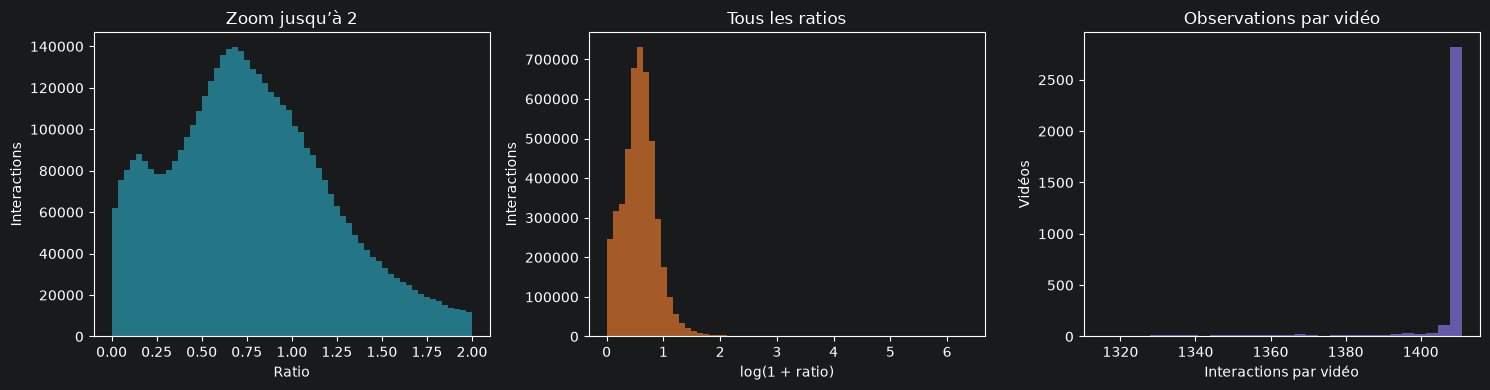

In [11]:
figure, axes = plt.subplots(1, 3, figsize=(15, 4))
ratios_du_zoom = donnees.loc[donnees.watch_ratio <= 2, "watch_ratio"]
axes[0].hist(ratios_du_zoom, bins=60, color="#247585")
axes[0].set(title="Zoom jusqu’à 2", xlabel="Ratio", ylabel="Interactions")
axes[1].hist(np.log1p(donnees.watch_ratio), bins=60, color="#a45b27")
axes[1].set(title="Tous les ratios", xlabel="log(1 + ratio)", ylabel="Interactions")
axes[2].hist(observations_video, bins=30, color="#635ba7")
axes[2].set(title="Observations par vidéo", xlabel="Interactions par vidéo", ylabel="Vidéos")
figure.tight_layout()
plt.show()

Le zoom conserve les valeurs supérieures à 2 dans les données. Le logarithme du graphique central rapproche visuellement les valeurs extrêmes. Une grande durée relative ne suffit pas à établir une satisfaction ou un nombre exact de relectures. La concentration des observations par vidéo aide à comprendre pourquoi leur simple nombre distingue peu les vidéos.

## 4. Construire trois partitions par utilisateur

Une **matrice** est un tableau à deux dimensions. Ici, une ligne représente un utilisateur et une colonne représente une vidéo. L’identifiant d’une vidéo peut être 5 464 même si le tableau a moins de 5 464 colonnes. Nous traduisons donc les identifiants en **positions**. Dans le catalogue trié [14, 27, 90], l’ID 27 se trouve en position 1, car Python commence à 0.

In [12]:
lignes_utilisateurs = np.searchsorted(ids_utilisateurs, donnees.user_id.to_numpy())
colonnes_videos = np.searchsorted(ids_videos, donnees.video_id.to_numpy())
ratios = np.full(forme_matrice, np.nan, dtype=np.float64)
ratios[lignes_utilisateurs, colonnes_videos] = donnees.watch_ratio.to_numpy(np.float64)

observe = np.isfinite(ratios)
etiquettes = (ratios >= SEUIL).astype(np.float32)
entrainement = np.zeros(forme_matrice, dtype=bool)
validation = np.zeros_like(entrainement)
test = np.zeros_like(entrainement)

Un **masque** est un tableau de vrais et de faux. Pour une vidéo observée, un seul des trois masques vaudra vrai. Une paire absente reste en dehors des trois. Nous conservons les ratios en double précision pour respecter le seuil du fichier.

L’entraînement sert à calculer les scores, la validation à choisir le modèle et le test à mesurer le résultat après ce choix. Nous prélevons 20 % pour le test, puis 25 % du reste pour la validation. Sur 100 observations, cela donne 20 pour le test, 20 pour la validation et 60 pour l’entraînement, aux arrondis près. Le découpage est aléatoire et non chronologique.

In [13]:
generateur_partition = np.random.default_rng(GRAINE)
for ligne in range(nombre_utilisateurs):
    videos_observees = np.flatnonzero(observe[ligne])
    graine_test = int(generateur_partition.integers(0, 2**31 - 1))
    reste, videos_test = train_test_split(videos_observees, test_size=0.2, random_state=graine_test)
    graine_validation = int(generateur_partition.integers(0, 2**31 - 1))
    videos_train, videos_val = train_test_split(reste, test_size=0.25, random_state=graine_validation)
    entrainement[ligne, videos_train] = True
    validation[ligne, videos_val] = True
    test[ligne, videos_test] = True

Les graines successives évitent d’imposer le même tirage aux utilisateurs ayant vu les mêmes vidéos. Nous vérifions que les trois partitions sont disjointes, couvrent les observations et contiennent assez de candidats pour former des listes de dix.

In [14]:
assert not (entrainement & validation).any()
assert not (entrainement & test).any()
assert not (validation & test).any()
assert np.array_equal(entrainement | validation | test, observe)
assert (validation.sum(axis=1) >= K).all()
assert (test.sum(axis=1) >= K).all()
assert (entrainement.sum(axis=0) > 0).all()
assert (entrainement.sum(axis=1) > 0).all()

bilan_partitions = []
for nom, masque in [("entraînement", entrainement), ("validation", validation), ("test", test)]:
    utilisateurs_presents = masque.any(axis=1)
    bilan_partitions.append({"partition": nom, "interactions": masque.sum(),
                             "utilisateurs": utilisateurs_presents.sum()})
display(pd.DataFrame(bilan_partitions))
print("Minimum d’observations d’entraînement par vidéo :", entrainement.sum(axis=0).min())
np.savez_compressed(sortie / "partitions.npz", users=ids_utilisateurs, items=ids_videos,
                    train=entrainement, validation=validation, test=test)

,partition,interactions,utilisateurs
0,entraînement,2805059,1411
1,validation,935611,1411
2,test,935900,1411


Minimum d’observations d’entraînement par vidéo : 753


Les tableaux enregistrés permettent de retrouver la partition de chaque paire. Pour évaluer un utilisateur, nous classerons uniquement les vidéos **observées** dans sa validation ou son test, y compris celles dont l’étiquette vaut zéro. L’exercice mesure donc un classement parmi des candidats observés. Il ne teste pas la recherche dans tout le catalogue.

## 5. Comment juger une liste ordonnée ?

Imaginons qu’un utilisateur a **4 vidéos positives** parmi ses candidats. Affichons seulement 3 vidéos. Leurs étiquettes, dans l’ordre, sont **[1, 0, 1]**. Nous retrouvons 2 positives. La **précision** vaut 2/3 et le **rappel** vaut 2/4. Le premier nombre parle de ce que nous affichons, le second de ce que nous avons retrouvé.

La **NDCG** tient compte des positions. Les poids des trois premières places sont 1, environ 0,631 et 0,5. Notre liste obtient 1 + 0 + 0,5 = 1,5. Le meilleur ordre possible placerait trois positives en tête, pour 1 + 0,631 + 0,5 ≈ 2,131. Notre NDCG vaut donc environ 0,704. Pour l’expérience réelle, la même règle s’applique aux **dix** premières places.

In [15]:
def mesurer_liste(pertinence_du_top, nombre_positifs, poids_positions):
    """Mesurer une liste dont les étiquettes sont déjà dans l’ordre recommandé."""
    positifs_retrouves = pertinence_du_top.sum()
    longueur = len(pertinence_du_top)
    precision = positifs_retrouves / longueur
    if nombre_positifs == 0:
        return precision, np.nan, np.nan

    rappel = positifs_retrouves / nombre_positifs
    gain_obtenu = pertinence_du_top @ poids_positions
    places_ideales = min(longueur, nombre_positifs)
    gain_ideal = poids_positions[:places_ideales].sum()
    return precision, rappel, float(gain_obtenu / gain_ideal)

Le symbole `@` multiplie chaque étiquette par le poids de sa position et additionne les produits. Lorsqu’il n’existe aucun positif chez un utilisateur, sa précision est zéro, tandis que son rappel et sa NDCG sont indéfinis.

In [16]:
def calculer_poids(longueur):
    positions = np.arange(1, longueur + 1)
    return 1 / np.log2(positions + 1)

exemple_metriques = mesurer_liste(np.array([1., 0., 1.]), 4, calculer_poids(3))
print("Précision, rappel et NDCG de l’exemple :", np.round(exemple_metriques, 3))
poids_du_top = calculer_poids(K)

Précision, rappel et NDCG de l’exemple : [0.667 0.5   0.704]


Un **score** indique l’ordre de préférence du modèle. Une règle de popularité donne une valeur par vidéo. Un modèle personnalisé donne une ligne de scores par utilisateur. Pour les deux formats, nous trions par score décroissant, puis par ID vidéo croissant en cas d’égalité.

In [17]:
def classer_candidats(candidats, scores_candidats, longueur):
    # lexsort utilise la dernière clé en priorité. Le signe moins fait passer les grands scores en tête.
    identifiants_candidats = ids_videos[candidats]
    ordre = np.lexsort((identifiants_candidats, -scores_candidats))
    return candidats[ordre[:longueur]]

def choisir_top_evaluation(scores, ligne, candidats):
    if scores.ndim == 1:
        scores_candidats = scores[candidats]
    else:
        scores_candidats = scores[ligne, candidats]
    assert len(candidats) >= K
    assert np.isfinite(scores_candidats).all()
    top = classer_candidats(candidats, scores_candidats, K)
    assert len(np.unique(top)) == K
    assert not entrainement[ligne, top].any()
    return top

Pour chaque utilisateur, la fonction suivante reçoit un **masque de candidats** et des **scores**. Elle renvoie une ligne de mesures et garde les dix positions retenues. Les étiquettes interviennent **après** le classement.

In [18]:
def evaluer(scores, masque, seuil=SEUIL, utilisateurs=None):
    if utilisateurs is None:
        utilisateurs = range(nombre_utilisateurs)
    mesures, listes = [], []
    for ligne in utilisateurs:
        candidats = np.flatnonzero(masque[ligne])
        top = choisir_top_evaluation(scores, ligne, candidats)
        pertinence_du_top = (ratios[ligne, top] >= seuil).astype(float)
        nombre_positifs = int((ratios[ligne, candidats] >= seuil).sum())
        precision, rappel, ndcg = mesurer_liste(pertinence_du_top, nombre_positifs, poids_du_top)
        mesures.append({
            "user_id": int(ids_utilisateurs[ligne]), "precision": precision,
            "recall": rappel, "ndcg": ndcg, "positifs_candidats": nombre_positifs,
            "nombre_candidats": len(candidats),
        })
        listes.append(top)
    return pd.DataFrame(mesures), np.asarray(listes)

Nous prenons la moyenne des mesures individuelles pour donner le même poids à chaque utilisateur ayant une mesure définie. La **couverture** compte les vidéos distinctes apparues dans toutes les listes. Si ces listes contiennent 12 vidéos différentes sur un catalogue de 30, elle vaut 12/30 = 40 %.

In [19]:
def resumer(nom, mesures, listes):
    videos_distinctes = np.unique(listes)
    return {
        "modele": nom,
        "Precision@10": mesures.precision.mean(),
        "Recall@10": mesures.recall.mean(),
        "NDCG@10": mesures.ndcg.mean(),
        "couverture_catalogue": len(videos_distinctes) / nombre_videos,
        "utilisateurs": len(mesures),
        "sans_positif": int((mesures.positifs_candidats == 0).sum()),
    }

## 6. Construire quatre règles de référence

Une **baseline** est une règle qui sert de point de comparaison. Les quatre règles sont le hasard, le nombre d’expositions, le nombre d’interactions positives et le taux positif lissé. Une exposition désigne ici une paire observée à l’entraînement. Une vidéo exposée 10 fois avec 4 interactions positives obtient deux comptes différents, 10 et 4.

In [20]:
expositions_par_video = entrainement.sum(axis=0).astype(np.float32)
interactions_positives_train = etiquettes * entrainement
positifs_par_video = interactions_positives_train.sum(axis=0)
total_positifs = positifs_par_video.sum()
total_expositions = expositions_par_video.sum()
taux_global = float(total_positifs / total_expositions)
print("Taux positif global d’entraînement :", taux_global)

Taux positif global d’entraînement : 0.47441035509109497


Multiplier par le masque met à zéro les cases hors entraînement. Avec **axis=0**, NumPy additionne les lignes de chaque colonne. On obtient donc un total par **vidéo**. Avec **axis=1**, on additionnerait les colonnes de chaque ligne, pour obtenir un total par **utilisateur**.

Le **lissage** rapproche le taux d’une vidéo du taux global, surtout si ses observations sont rares. Exemple fictif avec 4 positifs sur 10 et un taux global de 0,5. Le lissage ajoute le poids de 20 observations à ce taux. On obtient (4 + 20 × 0,5) / (10 + 20) ≈ 0,467. La valeur 20 est fixée dans le protocole.

In [21]:
LISSAGE = 20.0

def lisser(positifs, expositions, taux_de_reference):
    positifs_ajoutes = LISSAGE * taux_de_reference
    numerateur = positifs + positifs_ajoutes
    denominateur = expositions + LISSAGE
    return numerateur / denominateur

taux_lisse = lisser(positifs_par_video, expositions_par_video, taux_global)
generateur_hasard = np.random.default_rng(GRAINE)
scores_modeles = {
    "Aleatoire": generateur_hasard.random(forme_matrice, dtype=np.float32),
    "Nb_interactions": expositions_par_video,
    "Nb_pertinentes": positifs_par_video,
    "Taux_lisse": taux_lisse,
}

Nous évaluons les quatre règles sur les mêmes candidats de validation. Le tirage aléatoire est conservé pour toutes les comparaisons.

In [22]:
mesures_validation = []

def ajouter_resultat_validation(nom):
    mesures, listes = evaluer(scores_modeles[nom], validation)
    mesures_validation.append(resumer(nom, mesures, listes))

for nom in scores_modeles:
    ajouter_resultat_validation(nom)
display(pd.DataFrame(mesures_validation).round(5))

,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Aleatoire,0.47945,0.01524,0.47944,0.98798,1411,0
1,Nb_interactions,0.45386,0.01426,0.43389,0.03427,1411,0
2,Nb_pertinentes,0.89440,0.02951,0.90237,0.03006,1411,0
3,Taux_lisse,0.89957,0.02971,0.90616,0.03066,1411,0


Dans le tableau, compare le nombre d’expositions au nombre de positifs. Le second utilise déjà une information sur la réponse de l’utilisateur. Le taux lissé tient aussi compte du nombre d’occasions d’observer cette réponse.

## 7. Personnaliser le score avec la SVD

Le **filtrage collaboratif** exploite des régularités entre les réponses de plusieurs utilisateurs. Nous calculons d’abord le taux positif personnel à l’entraînement. Pour une personne dont ce taux est 0,6, une étiquette positive laisse un **résidu** de 1 − 0,6 = +0,4. Une étiquette négative laisse −0,6. Une case hors entraînement reçoit un résidu neutre de zéro.

In [23]:
positifs_par_utilisateur = interactions_positives_train.sum(axis=1)
expositions_par_utilisateur = entrainement.sum(axis=1)
moyenne_utilisateur = positifs_par_utilisateur / expositions_par_utilisateur
# Une colonne de moyennes permet de soustraire la bonne moyenne sur toute la ligne.
moyennes_en_colonne = moyenne_utilisateur[:, None]
ecarts_personnels = etiquettes - moyennes_en_colonne
residus = np.where(entrainement, ecarts_personnels, 0).astype(np.float32)

La **décomposition en valeurs singulières** (SVD) approxime cette matrice par des facteurs utilisateurs et vidéos. Le **rang** est le nombre de dimensions conservées. Il ne représente ni un nombre de catégories de vidéos ni la longueur de la liste recommandée. Pour obtenir des scores, nous multiplions les facteurs et rajoutons la moyenne personnelle.

In [24]:
def calculer_scores_svd(rang):
    gauche, valeurs, droite = randomized_svd(
        residus, n_components=rang, n_iter=5, random_state=GRAINE
    )
    facteurs_utilisateurs = (gauche * valeurs).astype(np.float32)
    facteurs_videos = droite.astype(np.float32)
    residus_estimes = facteurs_utilisateurs @ facteurs_videos
    scores_personnels = moyennes_en_colonne + residus_estimes
    return scores_personnels.astype(np.float32)

Pour le rang 16, chaque utilisateur a 16 facteurs et chaque vidéo aussi. Le produit matriciel calcule en une opération les combinaisons utilisateur-vidéo. Les zéros imputés participent à cette approximation. Les scores servent ensuite à ordonner les vidéos.

In [25]:
for rang in RANGS_SVD:
    debut = time.perf_counter()
    nom = f"SVD_{rang}"
    scores_modeles[nom] = calculer_scores_svd(rang)
    ajouter_resultat_validation(nom)
    print(nom, "· calcul et évaluation (secondes) :", round(time.perf_counter() - debut, 2))

table_validation = pd.DataFrame(mesures_validation)
lignes_svd = table_validation.modele.str.startswith("SVD_")
classement_svd = table_validation[lignes_svd].sort_values("NDCG@10", ascending=False)
meilleur_collaboratif = classement_svd.iloc[0].modele
display(classement_svd.round(5))
print("Rang retenu sur validation :", meilleur_collaboratif)

SVD_16 · calcul et évaluation (secondes) : 0.89
SVD_32 · calcul et évaluation (secondes) : 8.44
SVD_64 · calcul et évaluation (secondes) : 1.54


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
4,SVD_16,0.87144,0.02871,0.87431,0.49143,1411,0
5,SVD_32,0.84132,0.02765,0.84210,0.56658,1411,0
6,SVD_64,0.81991,0.02687,0.82074,0.62970,1411,0


Rang retenu sur validation : SVD_16


Le rang retenu est celui qui place le mieux les positifs en tête en moyenne sur la validation, d’après la NDCG@10. Le temps affiché inclut l’évaluation et dépend de la machine.

## 8. Combiner personnalisation et popularité

Les deux familles de scores ont des échelles différentes. Nous transformons chaque score en **rang relatif** dans le catalogue complet. Sur quatre vidéos, les positions 1, 2, 3 et 4 deviennent 0,25, 0,50, 0,75 et 1. Les ex æquo reçoivent le rang moyen. Pour la SVD, le classement se fait séparément pour chaque utilisateur.

In [26]:
positions_collaboratives = rankdata(scores_modeles[meilleur_collaboratif], axis=1, method="average")
rangs_collaboratifs = (positions_collaboratives / nombre_videos).astype(np.float32)
positions_popularite = rankdata(taux_lisse, method="average")
rangs_popularite = (positions_popularite / nombre_videos).astype(np.float32)

Le poids **alpha** règle la contribution du rang collaboratif. Avec alpha = 0,25, un rang collaboratif de 0,80 et un rang de popularité de 0,60 donnent 0,25 × 0,80 + 0,75 × 0,60 = 0,65. Ce poids porte sur chaque score. Il ne fixe pas un quota de vidéos dans la liste.

In [27]:
for alpha in POIDS_HYBRIDES:
    nom = f"Hybride_{alpha:.2f}"
    contribution_personnelle = alpha * rangs_collaboratifs
    contribution_popularite = (1 - alpha) * rangs_popularite[None, :]
    scores_modeles[nom] = contribution_personnelle + contribution_popularite
    ajouter_resultat_validation(nom)
table_validation = pd.DataFrame(mesures_validation)

Nous conservons le meilleur hybride, la meilleure règle de référence et le modèle à livrer. Pour ce dernier choix, tous les candidats sauf le hasard sont éligibles. Le tri stable conserve leur ordre de présentation lorsque deux NDCG sont identiques.

In [28]:
def classer_sur_validation(lignes):
    candidats = table_validation.loc[lignes]
    return candidats.sort_values("NDCG@10", ascending=False, kind="stable")

noms_references = ["Nb_interactions", "Nb_pertinentes", "Taux_lisse"]
classement_references = classer_sur_validation(table_validation.modele.isin(noms_references))
classement_hybrides = classer_sur_validation(table_validation.modele.str.startswith("Hybride_"))
classement_final = classer_sur_validation(table_validation.modele != "Aleatoire")
meilleure_reference = classement_references.iloc[0].modele
meilleur_hybride = classement_hybrides.iloc[0].modele
modele_retenu = classement_final.iloc[0].modele
display(classement_final.round(5))
print("Choix figé :", modele_retenu, "· Référence :", meilleure_reference)
table_validation.to_csv(sortie / "validation.csv", index=False)

,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
8,Hybride_0.25,0.90425,0.02990,0.90913,0.07454,1411,0
3,Taux_lisse,0.89957,0.02971,0.90616,0.03066,1411,0
7,Hybride_0.00,0.89957,0.02971,0.90616,0.03066,1411,0
9,Hybride_0.50,0.90071,0.02977,0.90563,0.13225,1411,0
2,Nb_pertinentes,0.89440,0.02951,0.90237,0.03006,1411,0
10,Hybride_0.75,0.89320,0.02949,0.89799,0.22453,1411,0
4,SVD_16,0.87144,0.02871,0.87431,0.49143,1411,0
11,Hybride_1.00,0.87144,0.02871,0.87431,0.49143,1411,0
5,SVD_32,0.84132,0.02765,0.84210,0.56658,1411,0
6,SVD_64,0.81991,0.02687,0.82074,0.62970,1411,0


Choix figé : Hybride_0.25 · Référence : Taux_lisse


À partir d’ici, les scores et les choix restent figés. Nous ne réentraînons pas sur entraînement + validation. Le test va mesurer comment les choix se comportent sur des interactions réservées.

## 9. Mesurer les performances sur le test réservé

Nous comparons les quatre références, le meilleur collaboratif, le meilleur hybride et le modèle retenu. Un même nom peut apparaître à deux titres. Le dictionnaire conserve la première occurrence de chaque nom pour évaluer chaque modèle une seule fois.

In [29]:
candidats_test = ["Aleatoire", *noms_references, meilleur_collaboratif, meilleur_hybride, modele_retenu]
noms_test = list(dict.fromkeys(candidats_test))
details_test = {}
bilans_test = []
for nom in noms_test:
    mesures, listes = evaluer(scores_modeles[nom], test)
    details_test[nom] = mesures
    bilans_test.append(resumer(nom, mesures, listes))

table_test = pd.DataFrame(bilans_test)
metriques = ["Precision@10", "Recall@10", "NDCG@10", "couverture_catalogue"]
assert table_test[metriques].ge(0).all().all()
assert table_test[metriques].le(1).all().all()
assert (table_test.utilisateurs == nombre_utilisateurs).all()
display(table_test.round(6))

,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Aleatoire,0.475124,0.015041,0.469818,0.983769,1411,0
1,Nb_interactions,0.455067,0.014365,0.434671,0.032762,1411,0
2,Nb_pertinentes,0.897236,0.029666,0.902839,0.031259,1411,0
3,Taux_lisse,0.902693,0.029855,0.909684,0.029757,1411,0
4,SVD_16,0.871226,0.028616,0.875383,0.491734,1411,0
5,Hybride_0.25,0.902197,0.029802,0.908052,0.076646,1411,0


Le rappel peut être faible même lorsque la précision est élevée. Si 9 des 10 vidéos affichées sont positives et que les candidats contiennent 300 positives, la précision vaut 9/10 et le rappel 9/300. La couverture, elle, porte sur les vidéos distinctes recommandées à l’ensemble des utilisateurs.

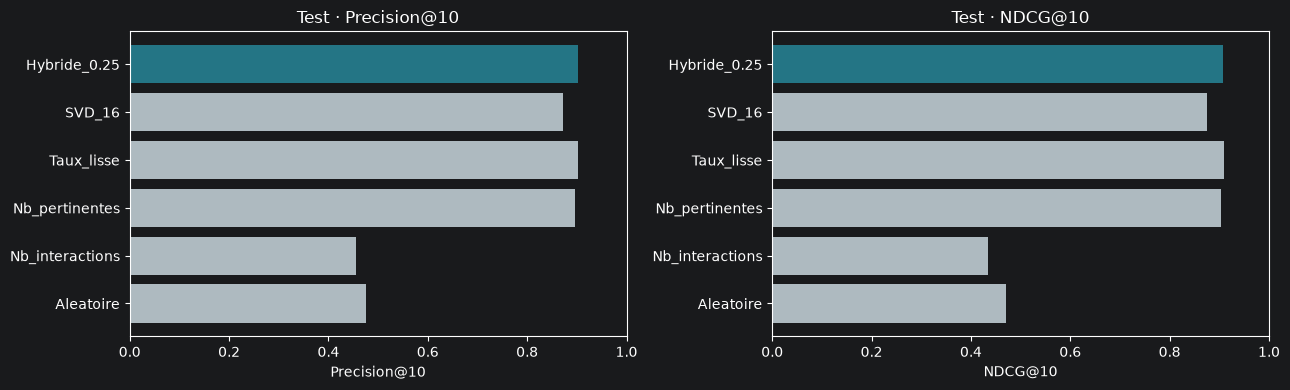

In [30]:
table_test.to_csv(sortie / "test_comparaison.csv", index=False)
tables_individuelles = []
couleurs = []
for nom in noms_test:
    tables_individuelles.append(details_test[nom].assign(modele=nom))
    couleurs.append("#247585" if nom == modele_retenu else "#aebac0")
pd.concat(tables_individuelles).to_csv(sortie / "test_par_utilisateur.csv", index=False)

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for axe, metrique in zip(axes, ["Precision@10", "NDCG@10"]):
    axe.barh(table_test.modele, table_test[metrique], color=couleurs)
    axe.set(xlabel=metrique, title="Test · " + metrique, xlim=(0, 1))
figure.tight_layout()
plt.show()

La barre colorée correspond au modèle choisi **avant** le test. Deux barres presque égales ne suffisent pas à conclure à un gain.

### Quelle incertitude sur la différence de NDCG ?

Pour chaque utilisateur, on soustrait sa NDCG de référence à sa NDCG avec le candidat. Un utilisateur à 0,93 et 0,90 apporte une différence de +0,03. Le **bootstrap apparié** tire au hasard des utilisateurs avec remise. Une personne peut figurer plusieurs fois dans un tirage, et ses deux scores restent associés. Nous calculons la moyenne de chaque tirage et gardons les bornes à 2,5 % et 97,5 % sur 2 000 tirages.

In [31]:
def bootstrap_difference(ndcg_modele, ndcg_reference, repetitions=2000):
    differences = np.asarray(ndcg_modele - ndcg_reference, dtype=float)
    differences = differences[np.isfinite(differences)]
    generateur = np.random.default_rng(GRAINE)
    taille_tirages = (repetitions, len(differences))
    tirages = generateur.choice(differences, size=taille_tirages, replace=True)
    moyennes = tirages.mean(axis=1)
    bornes = np.quantile(moyennes, [0.025, 0.975])
    return float(differences.mean()), bornes

Les deux séries sont dans le même ordre d’utilisateurs. Une différence négative signifie que la référence obtient une NDCG moyenne plus élevée. L’intervalle décrit l’incertitude conditionnelle à ce découpage.

In [32]:
comparaisons = []
ndcg_reference = details_test[meilleure_reference].ndcg
for nom in dict.fromkeys([meilleur_collaboratif, meilleur_hybride, modele_retenu]):
    difference, bornes = bootstrap_difference(details_test[nom].ndcg, ndcg_reference)
    comparaisons.append({
        "modele": nom, "reference": meilleure_reference, "difference_NDCG": difference,
        "IC95_bas": bornes[0], "IC95_haut": bornes[1],
    })
incertitude = pd.DataFrame(comparaisons)
display(incertitude.round(6))
incertitude.to_csv(sortie / "incertitude.csv", index=False)

,modele,reference,difference_NDCG,IC95_bas,IC95_haut
0,SVD_16,Taux_lisse,-0.034301,-0.041638,-0.027244
1,Hybride_0.25,Taux_lisse,-0.001632,-0.005590,0.002153


### Que devient le bilan si on change la définition d’un positif ?

Nous relisons les **mêmes classements** avec les seuils 0,5, 0,8 et 1. Une vidéo de ratio 0,9 restera à la même position. Elle sera comptée positive aux deux premiers seuils et négative au dernier. Aucun modèle n’est réentraîné pour ce diagnostic.

In [33]:
bilans_sensibilite = []
modeles_sensibilite = dict.fromkeys(["Aleatoire", meilleure_reference, modele_retenu])
for seuil_explore in [0.5, 0.8, 1.0]:
    for nom in modeles_sensibilite:
        mesures, listes = evaluer(scores_modeles[nom], test, seuil=seuil_explore)
        bilan = resumer(nom, mesures, listes)
        bilan["seuil"] = seuil_explore
        bilans_sensibilite.append(bilan)
sensibilite = pd.DataFrame(bilans_sensibilite)
display(sensibilite[["seuil", "modele", "Precision@10", "Recall@10", "NDCG@10"]].round(5))
sensibilite.to_csv(sortie / "sensibilite.csv", index=False)

,seuil,modele,Precision@10,Recall@10,NDCG@10
0,0.5,Aleatoire,0.73125,0.01516,0.72929
1,0.5,Taux_lisse,0.94833,0.01994,0.95191
2,0.5,Hybride_0.25,0.94685,0.01989,0.94951
3,0.8,Aleatoire,0.47512,0.01504,0.46982
4,0.8,Taux_lisse,0.90269,0.02985,0.90968
5,0.8,Hybride_0.25,0.90220,0.02980,0.90805
6,1.0,Aleatoire,0.32821,0.01513,0.32455
7,1.0,Taux_lisse,0.85684,0.04434,0.86965
8,1.0,Hybride_0.25,0.85344,0.04409,0.86482


### Comment accueillir un utilisateur sans historique ?

Nous retirons de l’entraînement de la popularité les interactions d’environ 10 % des utilisateurs, en arrondissant à l’entier supérieur. Leurs observations de test restent disponibles pour mesurer le **repli**. Le système peut ainsi proposer des vidéos grâce aux réponses des autres personnes.

In [34]:
generateur_repli = np.random.default_rng(GRAINE + 100)
taille_groupe = max(1, int(np.ceil(0.1 * nombre_utilisateurs)))
groupe_repli = np.sort(generateur_repli.choice(nombre_utilisateurs, size=taille_groupe, replace=False))
entrainement_repli = entrainement.copy()
entrainement_repli[groupe_repli] = False
assert not entrainement_repli[groupe_repli].any()

expositions_repli = entrainement_repli.sum(axis=0)
positifs_repli = (etiquettes * entrainement_repli).sum(axis=0)
taux_global_repli = positifs_repli.sum() / expositions_repli.sum()
scores_repli = lisser(positifs_repli, expositions_repli, taux_global_repli)
print("Utilisateurs retirés de l’entraînement du repli :", taille_groupe)

Utilisateurs retirés de l’entraînement du repli : 142


Nous comparons le repli et le hasard sur **les mêmes personnes et les mêmes candidats**. Cette expérience concerne une nouvelle personne dans un catalogue déjà connu. La situation d’une nouvelle vidéo reste à évaluer.

In [35]:
bilans_repli = []
for nom, scores in [("Repli_popularite_sans_historique", scores_repli),
                    ("Aleatoire_meme_groupe", scores_modeles["Aleatoire"])]:
    mesures, listes = evaluer(scores, test, utilisateurs=groupe_repli)
    bilans_repli.append(resumer(nom, mesures, listes))
table_repli = pd.DataFrame(bilans_repli)
display(table_repli.round(6))
table_repli.to_csv(sortie / "cold_start_utilisateur.csv", index=False)

,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Repli_popularite_sans_historique,0.911268,0.029981,0.919890,0.024346,142,0
1,Aleatoire_meme_groupe,0.486620,0.015268,0.479097,0.338443,142,0


### Préparer une conclusion à partir des sorties

Cette cellule lit les résultats qui viennent d’être obtenus. La couverture indique combien de vidéos distinctes ont été proposées à travers toutes les listes. Elle ne mesure ni la variété des thèmes ni la variété perçue par une personne.

In [36]:
resultats = table_test.set_index("modele")
retenu = resultats.loc[modele_retenu]
reference = resultats.loc[meilleure_reference]
comparaison = incertitude.set_index("modele").loc[modele_retenu]
if modele_retenu == meilleure_reference:
    interpretation = "La validation a retenu la référence elle-même."
elif comparaison.IC95_bas > 0:
    interpretation = "L’intervalle indique un gain de NDCG sur ce test."
elif comparaison.IC95_haut < 0:
    interpretation = "L’intervalle indique une perte de NDCG sur ce test."
else:
    interpretation = "L’intervalle inclut zéro. Le gain de NDCG reste incertain. L’équivalence reste aussi à démontrer."

synthese = (
    f"Modèle retenu en validation : {modele_retenu}. Référence : {meilleure_reference}.\n"
    f"Test sur {nombre_utilisateurs} utilisateurs. Précision@10 : {retenu['Precision@10']:.6f}.\n"
    f"NDCG@10 : {retenu['NDCG@10']:.6f} pour le modèle et {reference['NDCG@10']:.6f} pour la référence.\n"
    f"Différence : {comparaison.difference_NDCG:+.6f}. IC 95 % : [{comparaison.IC95_bas:+.6f}, {comparaison.IC95_haut:+.6f}].\n"
    f"Couverture : {retenu.couverture_catalogue:.2%} et {reference.couverture_catalogue:.2%}.\n"
    + interpretation
)
print(synthese)
(sortie / "conclusions.md").write_text(synthese, encoding="utf-8")

Modèle retenu en validation : Hybride_0.25. Référence : Taux_lisse.
Test sur 1411 utilisateurs. Précision@10 : 0.902197.
NDCG@10 : 0.908052 pour le modèle et 0.909684 pour la référence.
Différence : -0.001632. IC 95 % : [-0.005590, +0.002153].
Couverture : 7.66% et 2.98%.
L’intervalle inclut zéro. Le gain de NDCG reste incertain. L’équivalence reste aussi à démontrer.


370

**À l’oral.** « J’ai choisi les paramètres sur la validation. Pour le bilan, j’ai mesuré séparément la pertinence des dix premières vidéos et la part du catalogue couverte. » Appuie chaque affirmation sur la ligne correspondante du tableau. Une précision proche de 0,90 concerne l’étiquette de durée choisie. La satisfaction réelle et les performances sur les données de l’entreprise restent à mesurer. L’ancien essai sur 100 utilisateurs utilisait un autre protocole et ne permet pas de chiffrer un progrès entre les deux expériences.

## 10. Transformer les scores en recommandations

L’évaluation imposait une liste de candidats de validation ou de test. En démonstration, le service part du **catalogue**, enlève l’historique d’entraînement de l’utilisateur connu et retire les vidéos signalées comme déjà vues par l’application. Il peut donc renvoyer moins de K vidéos si elles ont presque toutes été exclues.

Pour une personne connue, nous lisons sa ligne de scores. Pour une personne inconnue, nous utilisons le taux lissé de l’entraînement principal. Ce sont des scores précalculés. Envoyer une vidéo dans `seen` la retire de la liste sans réentraîner le modèle.

In [37]:
scores_livres = scores_modeles[modele_retenu]
if scores_livres.ndim == 1:
    # Un modèle global donne la même ligne de scores à chaque personne connue.
    scores_livres = np.broadcast_to(scores_livres, forme_matrice).copy()

def indexer_utilisateurs(identifiants):
    positions = {}
    for position, identifiant in enumerate(identifiants):
        positions[int(identifiant)] = position
    return positions

positions_utilisateurs = indexer_utilisateurs(ids_utilisateurs)

La fonction suivante sera utilisée par le notebook et par l’API. Elle reçoit le catalogue, un score par vidéo, ainsi que les exclusions. Par exemple, si les scores classent les IDs [18, 25, 31] dans cet ordre et que 18 a déjà été vue, une demande de deux vidéos renvoie [25, 31].

In [38]:
def choisir_videos(catalogue, scores, historique, deja_vues, k):
    disponible = np.ones(len(catalogue), dtype=bool)
    if historique is not None:
        disponible = ~historique.copy()
    if deja_vues is not None:
        signalees = np.isin(catalogue, list(deja_vues))
        disponible &= ~signalees
    candidats = np.flatnonzero(disponible)
    ordre = np.lexsort((catalogue[candidats], -scores[candidats]))
    choix = candidats[ordre[:k]]
    return catalogue[choix].astype(int).tolist()

Le résultat doit pouvoir être lu par une application. Nous renvoyons l’ID utilisateur, le mode utilisé, les IDs vidéo classés et leur nombre réel. Les noms des champs sont conservés pour la démonstration.

In [39]:
def construire_reponse(user_id, videos, mode):
    return {"user_id": int(user_id), "mode": mode, "video_ids": videos, "nombre_retourne": len(videos)}

def recommander(user_id, k=10, deja_vues=None):
    if not isinstance(k, int) or not 1 <= k <= 100:
        raise ValueError("k doit être un entier entre 1 et 100")
    position = positions_utilisateurs.get(int(user_id))
    if position is None:
        scores, historique, mode = taux_lisse, None, "repli_popularite"
    else:
        scores = scores_livres[position]
        historique = entrainement[position]
        mode = modele_retenu
    videos = choisir_videos(ids_videos, scores, historique, deja_vues, k)
    return construire_reponse(user_id, videos, mode)

Essayons avec le premier ID connu et avec un ID supérieur au maximum du fichier. Le second doit déclencher le repli. Une deuxième requête signale que toute la première liste a été vue.

In [40]:
id_connu = int(ids_utilisateurs[0])
id_inconnu = int(ids_utilisateurs.max()) + 1
exemple_connu = recommander(id_connu)
exemple_inconnu = recommander(id_inconnu)
print(exemple_connu)
print(exemple_inconnu)

premiere_liste = exemple_connu["video_ids"]
assert len(premiere_liste) == K
assert len(set(premiere_liste)) == K
assert not set(premiere_liste).intersection(ids_videos[entrainement[0]])
deuxieme_liste = recommander(id_connu, deja_vues=premiere_liste)["video_ids"]
assert not set(premiere_liste).intersection(deuxieme_liste)
assert exemple_inconnu["mode"] == "repli_popularite"
try:
    recommander(id_connu, k=0)
except ValueError:
    print("k = 0 est bien rejeté.")
else:
    raise AssertionError("k = 0 aurait dû être rejeté.")

{'user_id': 14, 'mode': 'Hybride_0.25', 'video_ids': [5464, 8366, 3344, 7594, 5995, 314, 5365, 4715, 1445, 9261], 'nombre_retourne': 10}
{'user_id': 7163, 'mode': 'repli_popularite', 'video_ids': [6222, 2130, 1305, 7383, 5464, 4040, 600, 9178, 8524, 8298], 'nombre_retourne': 10}
k = 0 est bien rejeté.


### Exporter de quoi refaire une liste

Le fichier NPZ regroupe plusieurs tableaux NumPy. Les identifiants permettent de traduire les positions internes. Les scores donnent l’ordre, le masque `seen` élimine l’historique d’entraînement, et `popularity` sert au repli. Le manifeste JSON consigne l’expérience et deux réponses de référence.

In [41]:
np.savez_compressed(
    sortie / "modele_demo.npz",
    users=ids_utilisateurs, items=ids_videos, scores=scores_livres.astype(np.float32),
    seen=entrainement, popularity=taux_lisse.astype(np.float32),
)
manifeste = {
    "modele": modele_retenu, "collaboratif": meilleur_collaboratif, "hybride": meilleur_hybride,
    "baseline_reference": meilleure_reference, "seed": GRAINE, "seuil": SEUIL, "k": K,
    "csv_sha256": sha256, "versions": versions, "lignes": nombre_lignes,
    "utilisateurs": nombre_utilisateurs, "videos": nombre_videos,
    "split": "60/20/20 par utilisateur (approximatif, arrondis par groupe)",
    "candidats_test": "interactions observees du test par utilisateur",
    "exemple_connu": exemple_connu, "exemple_inconnu": exemple_inconnu,
}

def ecrire_json(nom_fichier, contenu):
    texte = json.dumps(contenu, ensure_ascii=False, indent=2)
    (sortie / nom_fichier).write_text(texte, encoding="utf-8")

ecrire_json("manifest.json", manifeste)

## 11. Servir le modèle par une API locale

Une **API** permet à un autre programme de poser une question au moteur. Exemple de requête : `/recommendations?user_id=14&k=10&seen=183,148`. Elle demande au plus dix vidéos pour l’utilisateur 14 et exclut aussi les vidéos 183 et 148.

Le service recharge une fois le fichier exporté. Une **classe** regroupe ici les tableaux du modèle et la méthode qui les utilise. `self` représente le service chargé. La méthode reprend les mêmes exclusions que le notebook. Pour un utilisateur connu, le contrat de l’API nomme le mode `modele_selectionne`. Le manifeste donne le nom précis du modèle.

In [42]:
class Recommender:
    def __init__(self, path=None):
        if path is None:
            path = Path(__file__).resolve().parent / "modele_demo.npz"
        with np.load(path, allow_pickle=False) as donnees_modele:
            self.users = donnees_modele["users"]
            self.items = donnees_modele["items"]
            self.scores = donnees_modele["scores"]
            self.seen = donnees_modele["seen"]
            self.pop = donnees_modele["popularity"]
        self.lookup = indexer_utilisateurs(self.users)

    def recommend(self, user_id, k=10, seen=()):
        if not 1 <= k <= 100:
            raise ValueError("k doit être entre 1 et 100")
        position = self.lookup.get(int(user_id))
        if position is None:
            scores, historique, mode = self.pop, None, "repli_popularite"
        else:
            scores, historique, mode = self.scores[position], self.seen[position], "modele_selectionne"
        videos = choisir_videos(self.items, scores, historique, seen, k)
        return construire_reponse(user_id, videos, mode)

Une **route** désigne l’opération demandée. Le code HTTP 200 signale une réponse réussie, 400 un paramètre invalide et 404 une route inconnue. La fonction de routage travaille sur le texte de la requête. Nous pourrons donc la tester sans connexion réseau.

In [43]:
from urllib.parse import parse_qs, urlparse

def traiter(path, service):
    adresse = urlparse(path)
    if adresse.path == "/health":
        return 200, {"status": "ok"}
    if adresse.path != "/recommendations":
        return 404, {"error": "Route inconnue"}
    try:
        parametres = parse_qs(adresse.query)
        utilisateur = int(parametres["user_id"][0])
        longueur = int(parametres.get("k", ["10"])[0])
        valeurs_vues = parametres.get("seen", [""])[0].split(",")
        deja_vues = [int(valeur) for valeur in valeurs_vues if valeur]
        return 200, service.recommend(utilisateur, longueur, deja_vues)
    except (KeyError, ValueError, TypeError):
        return 400, {"error": "Paramètres invalides : user_id entier, k entre 1 et 100, seen IDs séparés par virgules"}

Le gestionnaire HTTP appelle cette fonction, convertit le dictionnaire en texte JSON et envoie les octets de la réponse. Le serveur écoute sur l’interface locale de l’ordinateur. Démarrer une boucle serveur dans le notebook bloquerait l’exécution, donc nous préparons une commande à lancer dans un terminal.

In [44]:
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer

def lancer_serveur():
    service = Recommender()

    class Gestionnaire(BaseHTTPRequestHandler):
        def do_GET(self):
            statut, reponse = traiter(self.path, service)
            contenu = json.dumps(reponse, ensure_ascii=False).encode("utf-8")
            self.send_response(statut)
            self.send_header("Content-Type", "application/json; charset=utf-8")
            self.send_header("Content-Length", str(len(contenu)))
            self.end_headers()
            self.wfile.write(contenu)

    with ThreadingHTTPServer(("127.0.0.1", 8000), Gestionnaire) as serveur:
        print("API locale sur http://127.0.0.1:8000 · arrêt avec Ctrl+C")
        try:
            serveur.serve_forever()
        except KeyboardInterrupt:
            pass

Nous écrivons les définitions précédentes dans `api_demo.py`. Le script final est autonome avec Python, NumPy et le modèle NPZ dans le même dossier. `inspect.getsource` lit le code des fonctions définies ci-dessus, ce qui évite de maintenir une seconde copie de la logique de classement.

In [45]:
import inspect

imports_api = """import json
from pathlib import Path
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import parse_qs, urlparse
import numpy as np"""
definitions_api = [indexer_utilisateurs, choisir_videos, construire_reponse]
parties_script = [imports_api]
for definition in definitions_api:
    parties_script.append(inspect.getsource(definition).rstrip())
classe_service = "class Recommender:\n" + inspect.getsource(Recommender.__init__)
classe_service += "\n" + inspect.getsource(Recommender.recommend)
parties_script.extend([classe_service.rstrip(), inspect.getsource(traiter), inspect.getsource(lancer_serveur)])
parties_script.append('if __name__ == "__main__":\n    lancer_serveur()')
chemin_api = sortie / "api_demo.py"
chemin_api.write_text("\n\n\n".join(parties_script) + "\n", encoding="utf-8")
print("Commande depuis le dossier du notebook : python resultats_pedagogiques/api_demo.py")

Commande depuis le dossier du notebook : python resultats_pedagogiques/api_demo.py


### Tester le fichier qui sera utilisé pour la démonstration

Nous importons le script **depuis le disque** et rechargeons le NPZ. Pour un ID connu et un ID inconnu, nous comparons la liste ordonnée avant et après export. Nous vérifions aussi le rejet de requêtes incorrectes.

In [46]:
import importlib.util

description_module = importlib.util.spec_from_file_location("api_demo", chemin_api)
api = importlib.util.module_from_spec(description_module)
description_module.loader.exec_module(api)
service = api.Recommender()
assert service.recommend(id_connu)["video_ids"] == premiere_liste
assert service.recommend(id_inconnu)["video_ids"] == exemple_inconnu["video_ids"]
assert service.recommend(id_inconnu)["mode"] == "repli_popularite"
assert api.traiter("/health", service) == (200, {"status": "ok"})
for route, statut_attendu in [
    ("/inconnue", 404), ("/recommendations", 400),
    ("/recommendations?user_id=14&k=0", 400), ("/recommendations?user_id=abc", 400),
]:
    statut, reponse = api.traiter(route, service)
    assert statut == statut_attendu, route

Vérifions enfin une requête normale et une requête avec exclusions. Le statut et la liste doivent correspondre à ce que calcule la fonction locale.

In [47]:
route_connue = f"/recommendations?user_id={id_connu}&k=10"
statut, reponse = api.traiter(route_connue, service)
assert statut == 200 and reponse["video_ids"] == premiere_liste
ids_a_exclure = ",".join(str(identifiant) for identifiant in premiere_liste)
statut, reponse = api.traiter(route_connue + "&seen=" + ids_a_exclure, service)
assert statut == 200 and reponse["video_ids"] == deuxieme_liste
ecrire_json("tests.json", {
    "fonction_recommandation": "OK", "export_rechargement": "OK",
    "routes_hors_reseau": "OK", "serveur_HTTP_en_reseau": "non testé ici", "production": "non validée",
})
print("Fonction, export et routes hors réseau vérifiés.")

Fonction, export et routes hors réseau vérifiés.


### Faire la démonstration

1. Depuis le dossier du notebook, lancer `python resultats_pedagogiques/api_demo.py`.
2. Dans le navigateur, ouvrir `http://127.0.0.1:8000/health`, puis `http://127.0.0.1:8000/recommendations?user_id=14&k=10`.
3. Ajouter `&seen=` suivi du premier ID retourné, puis vérifier qu’il disparaît. Essayer ensuite l’ID inconnu affiché en section 10 pour voir le mode de repli.
4. Dans le terminal, arrêter le serveur avec **Ctrl+C**.

Les tests automatiques ci-dessus appellent directement la fonction de routage. Le transport HTTP et la tenue en charge demandent des essais distincts.

### Ce que tu peux défendre à l’oral

- **Pourquoi garder un modèle si la popularité obtient une meilleure NDCG sur le test ?** Le modèle a été sélectionné sur la validation. Le test sert à rendre compte de ce choix. Présente la différence de NDCG avec son intervalle et compare la couverture des deux méthodes.
- **Pourquoi appeler ce modèle hybride ?** Il combine deux ordres, l’un personnel et l’autre commun à tous. Les catégories et descriptions de vidéos disponibles dans KuaiRec ne sont pas utilisées ici.
- **Que reste-t-il à faire pour l’entreprise ?** Le moteur renvoie des identifiants KuaiRec. Dans l’application, le serveur devra associer les résultats à son propre catalogue, vérifier les autorisations et récupérer les vidéos avant affichage. Une collecte adaptée, un réentraînement et une évaluation sur les données de l’entreprise seront nécessaires. L’intégration réseau, la sécurité, la charge, les nouvelles vidéos et les effets métier restent à valider.